<a href="https://colab.research.google.com/github/masvetla/my-first-repo/blob/main/Svetlana_Manojlovic_Task1_Spotify_Top_10000.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

U ovom zadatku pokušaćemo odgovoriti na pitanje: "Koji je najbrži način da dođemo do slike o tome šta zaista pokreće publiku na Spotifyju: koje pesme, koji žanrovi i kakvi trendovi?"

Koristimo kagglehub za uvoz podataka i nakon toga prikazujemo osnovne informacije skupu podataka.


In [13]:
!pip install kagglehub --quiet

import kagglehub

# Preuzimanje podataka
path = kagglehub.dataset_download("joebeachcapital/top-10000-spotify-songs-1960-now")
import pandas as pd

# Učitavanje CSV fajla
df = pd.read_csv(path + "/top_10000_1960-now.csv")


In [14]:
df.info()
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Track URI             9999 non-null   object 
 1   Track Name            9998 non-null   object 
 2   Artist URI(s)         9997 non-null   object 
 3   Artist Name(s)        9998 non-null   object 
 4   Album URI             9997 non-null   object 
 5   Album Name            9998 non-null   object 
 6   Album Artist URI(s)   9997 non-null   object 
 7   Album Artist Name(s)  9997 non-null   object 
 8   Album Release Date    9997 non-null   object 
 9   Album Image URL       9995 non-null   object 
 10  Disc Number           9999 non-null   int64  
 11  Track Number          9999 non-null   int64  
 12  Track Duration (ms)   9999 non-null   int64  
 13  Track Preview URL     7102 non-null   object 
 14  Explicit              9999 non-null   bool   
 15  Popularity           

,Track URI,Track Name,Artist URI(s),Artist Name(s),Album URI,Album Name,Album Artist URI(s),Album Artist Name(s),Album Release Date,Album Image URL,...,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature,Album Genres,Label,Copyrights
0,spotify:track:1XAZlnVtthcDZt2NI1Dtxo,Justified & Ancient - Stand by the Jams,spotify:artist:6dYrdRlNZSKaVxYg5IrvCH,The KLF,spotify:album:4MC0ZjNtVP1nDD5lsLxFjc,Songs Collection,spotify:artist:6dYrdRlNZSKaVxYg5IrvCH,The KLF,1992-08-03,https://i.scdn.co/image/ab67616d0000b27355346b...,...,0.0480,0.0158,0.112000,0.4080,0.504,111.458,4.0,NaN,Jams Communications,"C 1992 Copyright Control, P 1992 Jams Communic..."
1,spotify:track:6a8GbQIlV8HBUW3c6Uk9PH,I Know You Want Me (Calle Ocho),spotify:artist:0TnOYISbd1XYRBk9myaseg,Pitbull,spotify:album:5xLAcbvbSAlRtPXnKkggXA,Pitbull Starring In Rebelution,spotify:artist:0TnOYISbd1XYRBk9myaseg,Pitbull,2009-10-23,https://i.scdn.co/image/ab67616d0000b27326d73a...,...,0.1490,0.0142,0.000021,0.2370,0.800,127.045,4.0,NaN,Mr.305/Polo Grounds Music/J Records,"P (P) 2009 RCA/JIVE Label Group, a unit of Son..."
2,spotify:track:70XtWbcVZcpaOddJftMcVi,From the Bottom of My Broken Heart,spotify:artist:26dSoYclwsYLMAKD3tpOr4,Britney Spears,spotify:album:3WNxdumkSMGMJRhEgK80qx,...Baby One More Time (Digital Deluxe Version),spotify:artist:26dSoYclwsYLMAKD3tpOr4,Britney Spears,1999-01-12,https://i.scdn.co/image/ab67616d0000b2738e4986...,...,0.0305,0.5600,0.000001,0.3380,0.706,74.981,4.0,NaN,Jive,P (P) 1999 Zomba Recording LLC
3,spotify:track:1NXUWyPJk5kO6DQJ5t7bDu,Apeman - 2014 Remastered Version,spotify:artist:1SQRv42e4PjEYfPhS0Tk9E,The Kinks,spotify:album:6lL6HugNEN4Vlc8sj0Zcse,"Lola vs. Powerman and the Moneygoround, Pt. On...",spotify:artist:1SQRv42e4PjEYfPhS0Tk9E,The Kinks,2014-10-20,https://i.scdn.co/image/ab67616d0000b2731e7c53...,...,0.2590,0.5680,0.000051,0.0384,0.833,75.311,4.0,NaN,Sanctuary Records,"C © 2014 Sanctuary Records Group Ltd., a BMG C..."
4,spotify:track:72WZtWs6V7uu3aMgMmEkYe,You Can't Always Get What You Want,spotify:artist:22bE4uQ6baNwSHPVcDxLCe,The Rolling Stones,spotify:album:0c78nsgqX6VfniSNWIxwoD,Let It Bleed,spotify:artist:22bE4uQ6baNwSHPVcDxLCe,The Rolling Stones,1969-12-05,https://i.scdn.co/image/ab67616d0000b27373d927...,...,0.0687,0.6750,0.000073,0.2890,0.497,85.818,4.0,NaN,Universal Music Group,"C © 2002 ABKCO Music & Records Inc., P ℗ 2002 ..."


Iz prethodnog vidimo da skup podataka sadrži 35 kolona.

Izračunavamo koliko pesama i koliko različitih izvođača ima.

In [15]:
total_songs = df.shape[0]
unique_artists = df['Artist Name(s)'].nunique()

print("Ukupno pesama:", total_songs)
print("Broj različitih izvođača:", unique_artists)


Ukupno pesama: 9999
Broj različitih izvođača: 4129


Ima ukupno 9999 pesama i 4129 različitih izvođača.

Pronaćićemo pet najpopularnijih pesama, izdvojićemo 10 izvođača sa najviše pesama i to prikazati grafički.

In [16]:
top5 = df.sort_values(by="Popularity", ascending=False).head(5)
top5[['Track Name', 'Artist Name(s)', 'Popularity']]


,Track Name,Artist Name(s),Popularity
2428,vampire,Olivia Rodrigo,98
9077,Cupid - Twin Ver.,FIFTY FIFTY,97
213,Flowers,Miley Cyrus,96
9039,I'm Good (Blue),"David Guetta, Bebe Rexha",95
1224,I Ain't Worried,OneRepublic,95


/tmp/ipython-input-4083690195.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_artists.values, y=top_artists.index, palette="pastel")


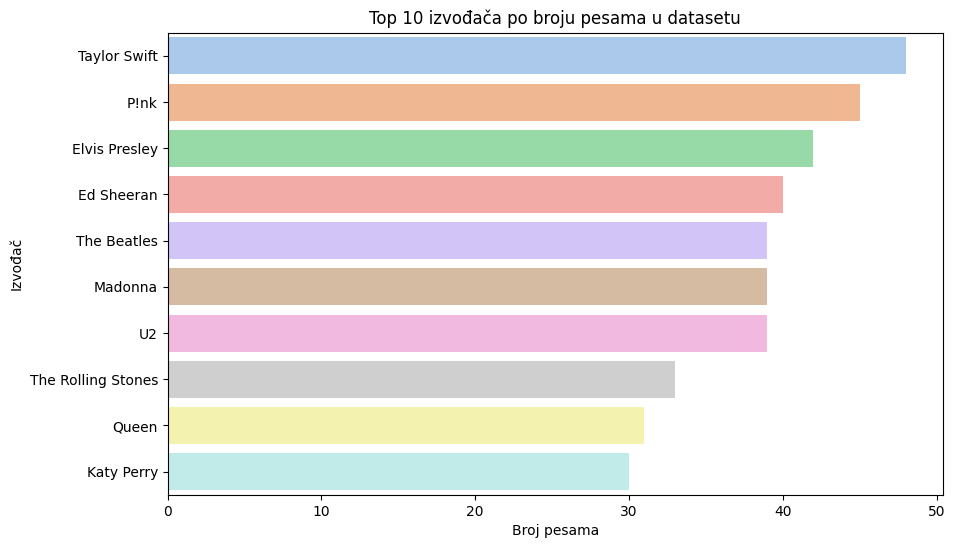

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

top_artists = df['Artist Name(s)'].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_artists.values, y=top_artists.index, palette="pastel")
plt.title("Top 10 izvođača po broju pesama u datasetu")
plt.xlabel("Broj pesama")
plt.ylabel("Izvođač")
plt.show()


Sa horizontalnog barplota vidimo da najviše pesama na listi ima Taylor Swift, Pink, Elvis Presley itd., redom.

Analiziramo trend: kako se broj eksplicitnih pesama menjao kroz godine i vizualizujemo podatke.

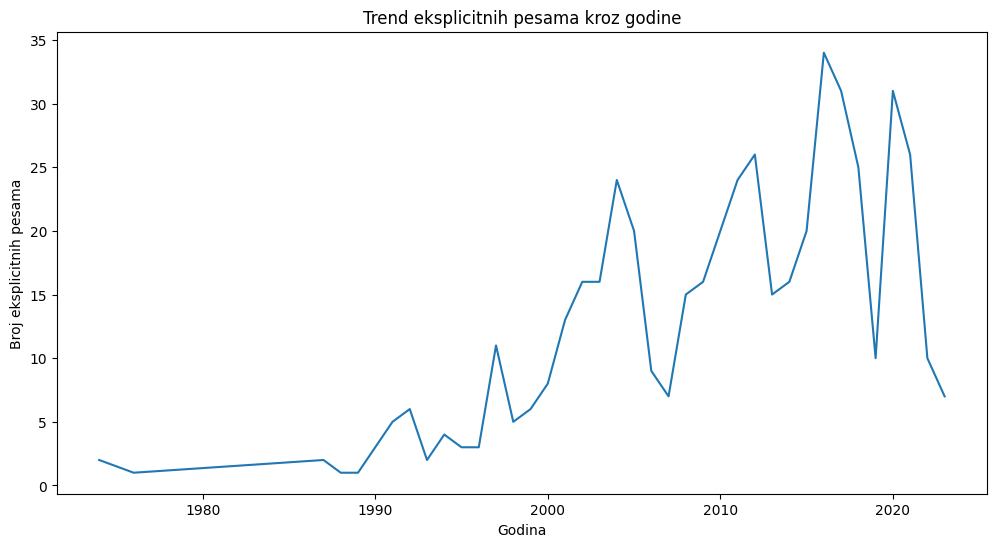

In [17]:
# Ekstrahovanje godine
df['Year'] = pd.to_datetime(df['Album Release Date'], errors='coerce').dt.year

# Eksplicitne pesme po godini
explicit_trend = df[df['Explicit'] == True].groupby('Year').size()

plt.figure(figsize=(12,6))
explicit_trend.plot(kind='line')
plt.title("Trend eksplicitnih pesama kroz godine")
plt.xlabel("Godina")
plt.ylabel("Broj eksplicitnih pesama")
plt.show()


Sa poslednjeg grafika vidimo kako je rastao broj pesama sa eksplicitnim sadržajem, posebno od 1998. godine.